# 02 — Kaggle JSON to YOLO WBC preprocessing

**Purpose:** Create an idempotent, single-class WBC training dataset with frozen, leakage-free splits.

**Required inputs:** Successful notebook 01; configured BCCD source.

**Saved outputs:** `data/processed/BCCD_YOLO/`, `outputs/preprocessing_report.json`, split manifests and before/after figure.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## 2. Convert and preserve splits

Only WBC objects become class 0. Kaggle `points.exterior` rectangle corners are normalized using actual image dimensions. The 205/87/72 source folder allocation is preserved exactly. Source files are never changed.

In [2]:
from src.preprocessing import preprocess, conversion_table
report = preprocess(cfg)
display(report)
print("Split policy:", report["split_reason"])
print("Clipped boxes:", len(report["clipped_boxes"]))

{'fingerprint': 'b23109fc103cd150a2a2207fe94316e03ebef4717e2081f4095a4b897bf41e10',
 'seed': 42,
 'source_format': 'kaggle_json',
 'split_reason': 'Preserved Kaggle train/val/test directory membership exactly.',
 'splits': {'train': 205, 'val': 87, 'test': 72},
 'total_wbc_boxes': 372,
 'source_root': 'D:\\Bcdatast',
 'clipped_boxes': [],
 'reused': False,
 'coordinate_policy': 'Use source rectangle corner pixels and actual image dimensions. Clip to [0,width] / [0,height]; no implicit one-pixel adjustment.',
 'processed_data_path': 'D:\\CellCancer\\leukemia-yolo\\data\\processed\\BCCD_YOLO'}

Split policy: Preserved Kaggle train/val/test directory membership exactly.
Clipped boxes: 0


## 3. Inspect round-trip and before/after

The table shows source JSON rectangle corners, normalized YOLO values and reversible pixel error.

,image,source_box_xyxy,clipped_box_xyxy,class_id,x_center,y_center,width,height,roundtrip_max_error_px
0,BloodImage_00007,"[193.0, 92.0, 387.0, 285.0]","[193.0, 92.0, 387.0, 285.0]",0,0.453125,0.392708,0.303125,0.402083,0.0


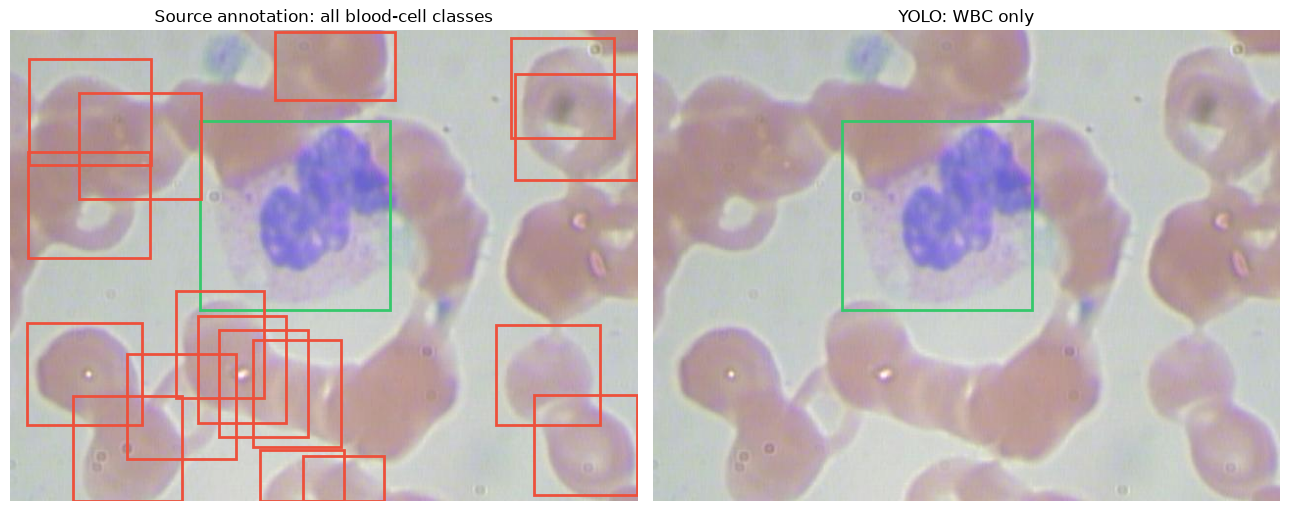

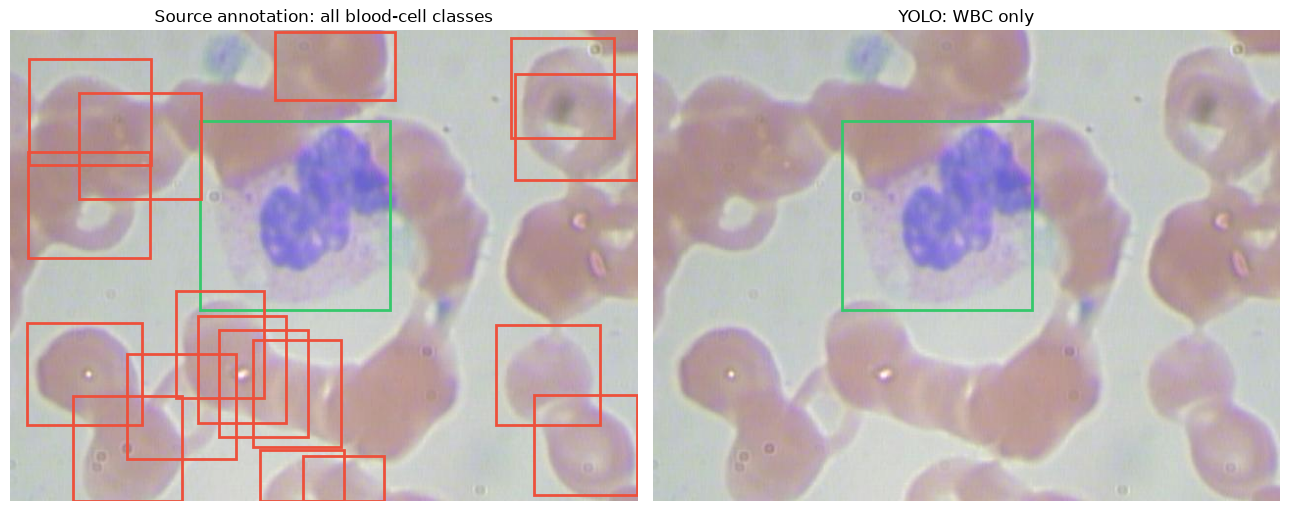

In [3]:
from src.bccd import inspect_dataset
from src.visualization import before_after
records = inspect_dataset(cfg)["records"]
selected = next((r for r in records if any(o["class"] == "WBC" for o in r["objects"])), None)
assert selected is not None, "No WBC examples in source"
table = conversion_table(selected)
display(table)
assert (table["roundtrip_max_error_px"] < 1e-4).all()
display(before_after(selected, cfg["processed_data_path"], out / "figures" / "preprocessing_examples.png"))

## 4. Verify saved dataset

This checks labels, source provenance, disjoint IDs and cross-split image hashes.

In [4]:
from src.validation import validate_processed
validation = validate_processed(cfg["processed_data_path"], out / "validation_report.json")
display(pd.DataFrame(validation["splits"]).T if "pd" in globals() else validation["splits"])
assert validation["ready"] and (out / "splits" / "manifest.json").is_file()
print("PASS — processed WBC dataset ready. Next: notebook 03.")

{'train': {'images': 205, 'wbc_boxes': 214, 'empty_labels': 1},
 'val': {'images': 87, 'wbc_boxes': 87, 'empty_labels': 1},
 'test': {'images': 72, 'wbc_boxes': 71, 'empty_labels': 4}}

PASS — processed WBC dataset ready. Next: notebook 03.


## Next notebook

Open **03_Dataset_Visualization.ipynb**.